In [203]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.options.display.float_format = '{:.5f}'.format
from sklearn.preprocessing import OneHotEncoder
from category_encoders import CountEncoder
from category_encoders.target_encoder import TargetEncoder

%matplotlib inline
import warnings
warnings.filterwarnings('ignore')


from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression,Ridge,LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


In [204]:
train = pd.read_csv('../data/train.csv')
policies = pd.read_csv('../data/policies.csv')
test = pd.read_csv('../data/test.csv')
samplesubmission = pd.read_csv('../data/SampleSubmission.csv')

In [205]:
test.shape

(4019, 14)

In [206]:
features  = ['sum_insured', 'product',
       'agent', 'class_of_business', 'risk_type', 'loss_date', 'client_type',
       'renewal_frequency', 'primary_cause', 'secondary_cause', 'branch']

In [207]:
categorical = ['product',
       'agent', 'class_of_business', 'risk_type', 'client_type',
       'renewal_frequency', 'primary_cause', 'secondary_cause', 'branch']

In [208]:
data  = pd.concat([train,test],axis=0)

In [209]:
data.shape

(13395, 15)

In [210]:
for col in categorical:
    data = pd.concat([data,pd.get_dummies(data[col],drop_first=True)] ,axis=1)

In [211]:
train.shape

(9376, 15)

In [212]:
# counts = policies.groupby('policy_number').count()['product_code']
# train = train.merge(counts, how='left',on='policy_number',suffixes='xx')
# train.head()
# test = test.merge(counts, how='left',on='policy_number',suffixes='xx')
# test.head()

In [213]:
# Convert datetime variables to datetime objects
data.loss_date = pd.to_datetime(data.loss_date, errors='coerce')

# Confirm that the dates have been converted successfully 
data.loss_date.describe()

# Extract day, month and year from the loss date column
# day
data['loss_date_day'] = data.loss_date.dt.day

# month
data['loss_date_month'] = data.loss_date.dt.month
 
# year
data['loss_date_year'] = data.loss_date.dt.year

# Preview engineered date features
data[['loss_date', 'loss_date_day', 'loss_date_month', 'loss_date_year']].head()

,loss_date,loss_date_day,loss_date_month,loss_date_year
0,2021-05-13,13,5,2021
1,2018-05-13,13,5,2018
2,2018-08-18,18,8,2018
3,2018-12-20,20,12,2018
4,2018-11-07,7,11,2018


In [214]:
train = data[:9376]
test = data[9376:]
print(train.shape)
print(test.shape)

(9376, 257)
(4019, 257)


In [215]:
data.shape

(13395, 257)

In [217]:
to_encode = ['product']
cEncoder = TargetEncoder(cols=to_encode)
cEncoder.fit(train[to_encode],train.target)
train = train.join(cEncoder.transform(train[to_encode]).add_suffix('_count'))
# cEncoder.fit(test[to_encode])
test = test.join(cEncoder.transform(test[to_encode]).add_suffix('_count'))

In [218]:
train.shape

(8472, 258)

In [219]:
train.head()

,claim_id,policy_number,claim_number,sum_insured,product,agent,class_of_business,risk_type,loss_date,client_type,...,br00006,br00007,br00008,br00009,br00010,br00011,loss_date_day,loss_date_month,loss_date_year,product_count
1,ID_KQ5TJMVLJ4EP,pol000006869,claim0005272,16000.00000,prod00005,ag00226,cob00010,rt00032,2018-05-13,ct0003,...,0,0,0,0,0,0,13,5,2018,2632.13026
2,ID_NYHI7WJGGIAE,pol000006135,claim0004147,3000.00000,prod00029,ag00037,cob00010,rt00026,2018-08-18,ct0003,...,0,0,0,0,0,0,18,8,2018,2002.01313
3,ID_ROMMDCXYUXN5,pol000008991,claim0009962,6000.00000,prod00005,ag00037,cob00009,rt00032,2018-12-20,ct0003,...,0,0,0,0,0,0,20,12,2018,2632.13026
4,ID_2OTD9NX8L73D,pol000007768,claim0007346,26850.00000,prod00015,ag00226,cob00034,rt00023,2018-11-07,ct0001,...,0,0,0,0,0,0,7,11,2018,9913.89850
5,ID_H22FLDGRJ0JR,pol000005951,claim0002227,80000.00000,prod00015,ag00037,cob00034,rt00023,2019-12-03,ct0001,...,0,0,0,0,0,0,3,12,2019,9913.89850


In [220]:
feature_cols = [col for col in train.columns if col not in ['claim_id', 'policy_number', 'claim_number','product', 'agent', 'class_of_business', 'risk_type', 'loss_date', 'client_type', 'renewal_frequency', 'primary_cause', 'secondary_cause', 'branch','target']]

# feature_cols

In [239]:

X = train[feature_cols]
y = train.target

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.5, random_state=123)

# Train model
model = XGBRegressor(n_estimators=500)
model.fit(X, y)
# model.fit(X_train, y_train)

# Make predictions
super_pred1 = model.predict(X)

# Check the MAE score of the model
# print(f'LinearRegression MAE score on the X_test is: {mean_absolute_error(y_test, y_pred)}')

In [240]:

# Train model2
model2 = LGBMRegressor(n_estimators=500)
model2.fit(X, y)

# Make predictions
super_pred2 = model2.predict(X)

# Check the MAE score of the model
# print(f'LinearRegression MAE score on the X_test is: {mean_absolute_error(y_test, y_pred)}')

In [241]:
X['super1'] = super_pred1
X['super2'] = super_pred2

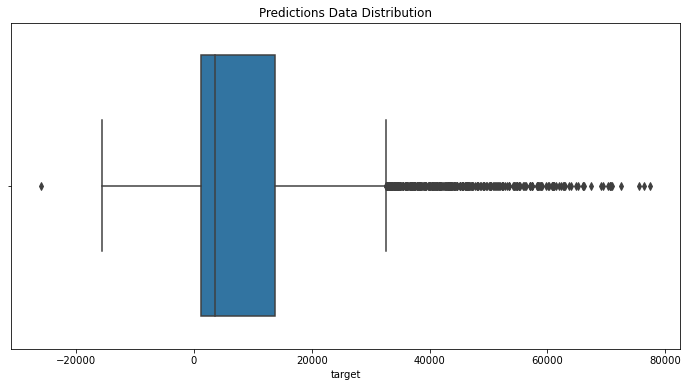

In [242]:
# Make prediction on the test set
test_df = test[feature_cols]
predictions = model.predict(test_df)


# # Create a submission file
sub_file = samplesubmission.copy()
sub_file.target = predictions

# Check the distribution of your predictions
plt.figure(figsize=(12, 6))
sns.boxplot(sub_file.target)
plt.title('Predictions Data Distribution')

# Write to csv file to submit to Zindi
sub_file.to_csv("XGBMout2.csv", index = False)

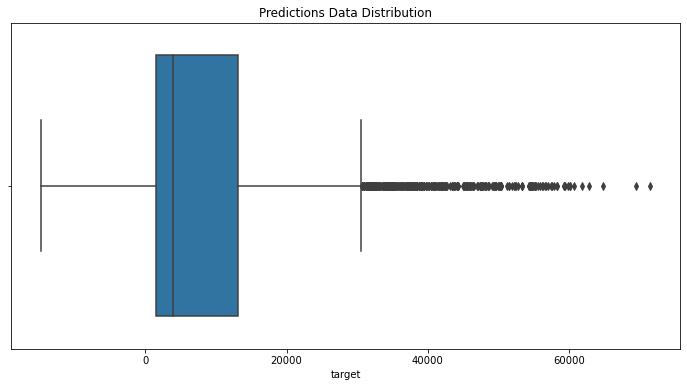

In [243]:
# Make prediction on the test set
test_df = test[feature_cols]
predictions2 = model2.predict(test_df)

# # Create a submission file
sub_file = samplesubmission.copy()
sub_file.target = predictions2

# Check the distribution of your predictions
plt.figure(figsize=(12, 6))
sns.boxplot(sub_file.target)
plt.title('Predictions Data Distribution')

# Write to csv file to submit to Zindi
sub_file.to_csv("LGBMout2.csv", index = False)

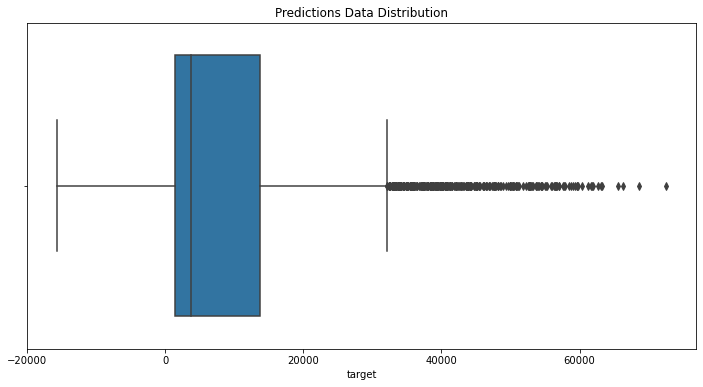

In [244]:
blend = predictions * .5 + predictions2 * .5

sub_file.target = blend

# Check the distribution of your predictions
plt.figure(figsize=(12, 6))
sns.boxplot(sub_file.target)
plt.title('Predictions Data Distribution')

# Write to csv file to submit to Zindi
sub_file.to_csv("BLENDout2.csv", index = False)

In [245]:
test['super1'] = predictions
test['super2'] = predictions2

In [237]:
test.head()

,claim_id,policy_number,claim_number,sum_insured,product,agent,class_of_business,risk_type,loss_date,client_type,...,br00008,br00009,br00010,br00011,loss_date_day,loss_date_month,loss_date_year,product_count,super1,super2
0,ID_4RO0KZI9BBW2,pol000007115,claim0005757,300000.00000,prod00005,ag00068,cob00009,rt00032,2021-03-11,ct0003,...,0,0,0,0,11,3,2021,2632.13026,34212.07812,36299.77651
1,ID_GTE9ZUJ9GZ97,pol000006008,claim0003037,2700000.00000,prod00015,ag00064,cob00034,rt00023,2020-06-25,ct0001,...,0,0,0,0,25,6,2020,9913.89850,55446.20312,39553.78801
2,ID_RUVIYRKWZ4RG,pol000007651,claim0006507,4071352.00000,prod00012,ag00021,cob00016,rt00015,2019-03-14,ct0001,...,0,0,0,0,14,3,2019,6963.42973,1571.12720,-195.05446
3,ID_J81X8SWU6JYN,pol000010981,claim0013636,0.00000,prod00002,ag00037,cob00002,rt00002,2018-12-04,ct0001,...,0,0,0,0,4,12,2018,9338.72119,3899.07544,6954.92821
4,ID_94NM3JJAWWOQ,pol000005926,claim0001750,1607178.00000,prod00015,ag00037,cob00034,rt00023,2019-09-18,ct0001,...,0,0,0,0,18,9,2019,9913.89850,7936.72510,9280.79360


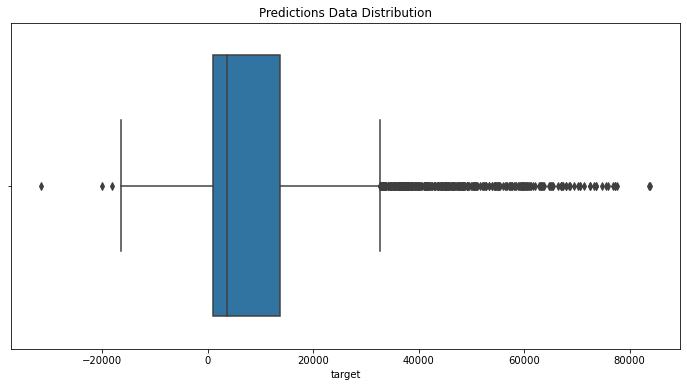

In [246]:

meta_model = LinearRegression()
meta_model.fit(X,y)




# # Make prediction on the test set
test_df = test[feature_cols+['super1','super2']]
meta_prediction = meta_model.predict(test_df)

# # # Create a submission file
sub_file = samplesubmission.copy()
sub_file.target = meta_prediction

# # Check the distribution of your predictions
plt.figure(figsize=(12, 6))
sns.boxplot(sub_file.target)
plt.title('Predictions Data Distribution')

# # Write to csv file to submit to Zindi
sub_file.to_csv("META.csv", index = False)

In [228]:
model2.feature_importances_.plot()

AttributeError: 'numpy.ndarray' object has no attribute 'plot'